# 04 · Ajuste y selección por negocio

Recalcula los resúmenes de las 90 configuraciones históricas. Este modo no inicia nuevas búsquedas, no consume servicios externos y mantiene la decisión registrada.

**Alcance de validación.** 2014J ya se había observado en una versión anterior. **No es una prueba final independiente ni un hold-out de un solo uso.** Separar personas y ajustar transformaciones dentro de cada fold evita fugas directas, pero no elimina el conocimiento previo de sus resultados. Las cifras sobre 2014J describen este histórico; la decisión institucional necesita una cohorte futura sin consultar, con protocolo fijado antes de conocer resultados.

In [1]:
from pathlib import Path
import os, sys, json, hashlib
here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p/'src/notebooks.py').is_file()), None)
if ROOT is None and (here/'proyecto_final/src/notebooks.py').is_file():
    ROOT = here/'proyecto_final'
assert ROOT is not None, 'Abrir desde proyecto_final o notebooks.'
sys.path.insert(0, str(ROOT))
os.environ['MPLCONFIGDIR'] = str(ROOT/'.local/matplotlib')
os.environ['PSET4_MODEL_MODE'] = 'fixture'
from IPython.display import display, Markdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.notebooks import evidencia
from src.datos import sha256
E = evidencia()
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 32)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
%matplotlib inline
print('Ejecución local de evidencia congelada. Sin llamadas LLM, nuevos entrenamientos ni cambios en Registry.')


Ejecución local de evidencia congelada. Sin llamadas LLM, nuevos entrenamientos ni cambios en Registry.


## Revisar todas las configuraciones

Treinta configuraciones por cada una de tres familias. La métrica principal es cobertura de Fail con cupos iguales; AP ayuda a diagnosticar, sin sustituir el objetivo de negocio.

,family,config_index,cv_coverage_mean,cv_coverage_std,cv_ap_fail_mean,ap_gap,run_id
45,boosting,15,0.233982,0.009338,0.583027,0.042358,dc2fa9bb8bee4944bd00611a6ac5c34f
2,lineal,2,0.232359,0.005617,0.556657,0.013842,bb2b400975994efdb01ea418118dda67
72,bayes,12,0.228240,0.010213,0.538137,0.005860,e7c7aeb2d49b4f14bdbcbe39b30197c7


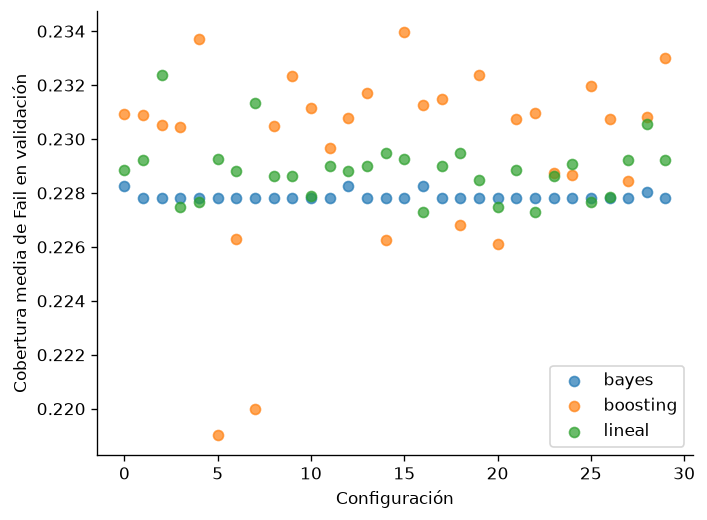

In [2]:
trials=E['tuning']['configurations']; assert len(trials)==90
for trial in trials:
    assert len(trial['folds'])==5
    np.testing.assert_allclose(trial['cv_coverage_mean'],np.mean([f['test_coverage'] for f in trial['folds']]))
    np.testing.assert_allclose(trial['cv_ap_fail_mean'],np.mean([f['test_ap_fail'] for f in trial['folds']]))
table=pd.DataFrame([{k:t[k] for k in ['family','config_index','cv_coverage_mean','cv_coverage_std','cv_ap_fail_mean','ap_gap','run_id']} for t in trials])
assert table.groupby('family').size().eq(30).all()
best=table.sort_values(['cv_coverage_mean','cv_ap_fail_mean'],ascending=False).groupby('family',sort=False).head(1)
display(best)
for family,group in table.groupby('family'):
    plt.scatter(group.config_index,group.cv_coverage_mean,label=family,alpha=.7)
plt.xlabel('Configuración'); plt.ylabel('Cobertura media de Fail en validación');plt.legend();plt.show()


## Conservar la decisión previa a la evaluación retrospectiva

HGB logra la mayor cobertura media, pero su ventaja frente a Logística es menor que la variación entre folds. Esto no prueba superioridad estable. Una reconstrucción de carpetas o una nueva ejecución no vuelve independiente a 2014J.

In [3]:
decision=E['decision']['content']
assert decision['v2_holdout_evaluated'] is False and decision['holdout_previously_observed_in_v1'] is True
display(pd.DataFrame([{'rol':role,**{k:decision[role][k] for k in ['family','cv_coverage_mean','cv_coverage_std','cv_ap_fail_mean','run_id']}} for role in ['winner','challenger']]))
assert decision['winner']['family']=='boosting'
print('Diferencia de cobertura:',decision['winner_challenger_difference'])
print('Referencia de dispersión:',decision['fold_variation_reference'])
print('Supera la variación:',decision['difference_exceeds_fold_variation'])
display(pd.DataFrame(decision['tuning_improvements']))
print('Parámetros elegidos:',decision['winner'].get('params'))


,rol,family,cv_coverage_mean,cv_coverage_std,cv_ap_fail_mean,run_id
0,winner,boosting,0.233982,0.009338,0.583027,dc2fa9bb8bee4944bd00611a6ac5c34f
1,challenger,lineal,0.232359,0.005617,0.556657,bb2b400975994efdb01ea418118dda67


Diferencia de cobertura: 0.0016225800505769716
Referencia de dispersión: 0.009338351412435388
Supera la variación: False


,family,default_run_id,tuned_run_id,delta_coverage,cv_spread_reference,improvement_exceeds_fold_variation,interpretation
0,lineal,7f75bbbab6ed4f56b58caa0850529b34,bb2b400975994efdb01ea418118dda67,0.003134,0.008012,False,sin mejora demostrada frente a la variación en...
1,boosting,61ef18564a504ec4bc39e454cbe1f8e9,dc2fa9bb8bee4944bd00611a6ac5c34f,0.005908,0.009338,False,sin mejora demostrada frente a la variación en...
2,bayes,dccc18435ccf489794cadd3ce4903342,e7c7aeb2d49b4f14bdbcbe39b30197c7,0.000422,0.010680,False,sin mejora demostrada frente a la variación en...


Parámetros elegidos: {'early_stopping': False, 'l2_regularization': 0.2387981007415031, 'learning_rate': 0.021812743276338767, 'max_depth': 8, 'max_iter': 160, 'max_leaf_nodes': 7, 'min_samples_leaf': 80}


## Lectura final

Los resultados reproducidos pertenecen a los experimentos registrados. La fecha de ejecución de este notebook no los convierte en evidencia nueva de generalización. Consulte `README.md` para insumos, dependencias y comandos del pipeline completo.